# Used Car Price Regression

Pricing a used car from age, mileage, power, fuel type, transmission and brand, on real listings. The data is `KTHESAT/european-used-cars-100k-sample` on Hugging Face (CC BY-NC 4.0): 100K listings scraped from mobile.de and AutoScout24. The raw fields are messy (German labels, a few registration years in the future, a 10-million-euro "price"), so I clean them first and then work with a random 20,000-row sample to keep the tree models fast on CPU.

Predicting on log price because car prices are heavily right-skewed and the residual distribution gets a lot more sensible when I take logs.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, r2_score

DATA_DIR = Path("../../data/used_cars")

In [2]:
pq_path = DATA_DIR / "european_used_cars_100k.parquet"
if not pq_path.exists():
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    pd.read_parquet("https://huggingface.co/datasets/KTHESAT/european-used-cars-100k-sample/"
                    "resolve/main/european_used_cars_100k.parquet").to_parquet(pq_path)
raw = pd.read_parquet(pq_path)

def fuel_group(s):
    s = str(s).lower()
    if "hybrid" in s or "/" in s: return "hybrid"
    if "elektro" in s or "electri" in s: return "electric"
    if "diesel" in s: return "diesel"
    if "benzin" in s or "super" in s or "petrol" in s or "essence" in s: return "petrol"
    return "other"

def gearbox(s):
    s = str(s).lower()
    if s.startswith("automat") or "halbauto" in s or "automatique" in s: return "automatic"
    if "schalt" in s or "manu" in s: return "manual"
    return "other"

SCRAPE_YEAR = 2026  # listings were collected in 2026, so age is measured from there
df = pd.DataFrame({
    "brand": raw["make"].str.lower(),
    "year": raw["first_registration_year"],
    "km": raw["mileage_km"],
    "power_hp": raw["power_hp"],
    "fuel": raw["fuel_type"].map(fuel_group),
    "transmission": raw["transmission"].map(gearbox),
    "price": raw["price_eur"],
})
df = df[df.year.between(1995, SCRAPE_YEAR) & df.price.between(500, 300_000)
        & df.km.between(1_000, 500_000) & df.power_hp.between(40, 800)].dropna()
# keep the 15 most common brands, lump the rest
top = df["brand"].value_counts().index[:15]
df["brand"] = df["brand"].where(df["brand"].isin(top), "other")
print(f"after cleaning: {len(df):,} listings")
df = df.sample(n=20_000, random_state=31).reset_index(drop=True)

print(f"sample used for modeling: {df.shape}")
df.describe(include='all').T.head(10)

after cleaning: 84,635 listings
sample used for modeling: (20000, 7)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
brand,20000,16,other,5526,NaN,NaN,NaN,NaN,NaN,NaN,NaN
year,20000.0,NaN,NaN,NaN,2019.77005,5.518006,1995.0,2017.0,2021.0,2024.0,2026.0
km,20000.0,NaN,NaN,NaN,80541.76095,68724.916171,1000.0,25044.0,64167.0,117864.0,480000.0
power_hp,20000.0,NaN,NaN,NaN,188.48185,119.397973,41.0,116.0,150.0,204.0,797.0
fuel,20000,5,petrol,9608,NaN,NaN,NaN,NaN,NaN,NaN,NaN
transmission,20000,3,automatic,12738,NaN,NaN,NaN,NaN,NaN,NaN,NaN
price,20000.0,NaN,NaN,NaN,27341.840429,29928.049634,550.0,12800.0,19990.0,30999.0,299995.0


In [3]:
df["age"] = SCRAPE_YEAR - df["year"]
df["log_price"] = np.log(df["price"])

X_df = pd.get_dummies(df.drop(columns=["price", "log_price", "year"]),
                       columns=["brand", "fuel", "transmission"], drop_first=True)
feature_names = X_df.columns.tolist()
X = X_df.values.astype(float)
y = df["log_price"].values

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=31)

models = {
    "Ridge": Pipeline([("sc", StandardScaler()), ("r", Ridge(alpha=1.0))]),
    "RF":    RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=31, n_jobs=2),
    "GBM":   GradientBoostingRegressor(n_estimators=300, max_depth=3, learning_rate=0.05, random_state=31),
}

for name, m in models.items():
    m.fit(X_tr, y_tr)
    pred = m.predict(X_te)
    # report MAE on the original (un-logged) scale so the number is interpretable
    mae_dollars = mean_absolute_error(np.exp(y_te), np.exp(pred))
    print(f"{name:5s}  R2 (log): {r2_score(y_te, pred):.3f}   MAE (EUR): {mae_dollars:,.0f}")

Ridge  R2 (log): 0.819   MAE (EUR): 7,100


RF     R2 (log): 0.892   MAE (EUR): 4,912


GBM    R2 (log): 0.876   MAE (EUR): 5,763


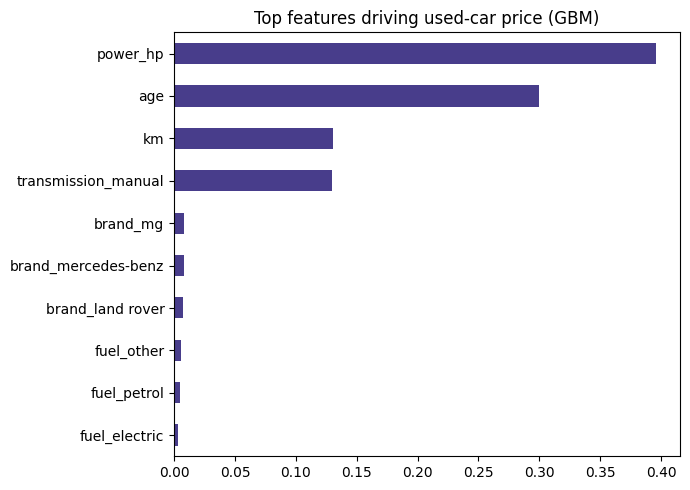

power_hp               0.396
age                    0.300
km                     0.130
transmission_manual    0.130
brand_mg               0.008
brand_mercedes-benz    0.008
brand_land rover       0.007
fuel_other             0.006
fuel_petrol            0.005
fuel_electric          0.004
dtype: float64


In [4]:
gbm = models["GBM"]
imp = pd.Series(gbm.feature_importances_, index=feature_names).sort_values(ascending=False).head(10)
imp.plot(kind="barh", figsize=(7, 5), color="darkslateblue")
plt.gca().invert_yaxis()
plt.title("Top features driving used-car price (GBM)")
plt.tight_layout(); plt.show()
print(imp.round(3))

## Takeaways

On 4,000 held-out listings, the random forest does best (R2 0.892 on log price, MAE about EUR 4,900), then gradient boosting (0.876, EUR 5,760), then ridge (0.819, EUR 7,100). Typical prices sit around EUR 20,000, so the forest is off by roughly a quarter of a median car's price on average, with the expensive cars pulling that up.

Engine power is the top feature for the GBM (0.40 of the importance), ahead of age (0.30), mileage (0.13) and manual vs automatic gearbox (0.13). Power is standing in for a lot here: it separates a base hatchback from the sporty or premium version of the same model. Individual brands barely register once power is in the model, which surprised me a bit.

Working on the log scale matters more than the choice of model. Prices run from EUR 550 to almost 300K in the cleaned data, and on raw price the squared-error fits get dragged around by the handful of very expensive cars.

If this were a real product I'd want: the model name and trim (the data has them, I left them out to keep the feature set small), the seller country, accident history, and whether the listing price is the final price. The cleaning step also made calls I'd want to revisit, like dropping listings under 1,000 km (mostly new or demo cars).